In [19]:
from pathlib import Path
import os

# if you want to see where the notebook kernel thinks it is
print("CWD:", Path.cwd())

# ✅ force repo root explicitly
PROJECT_ROOT = Path("/Users/dev/Desktop/graphCeylon-API")
print("PROJECT_ROOT:", PROJECT_ROOT)

INPUT_CSV = PROJECT_ROOT / "data/recommender_service/clean/sltda_arrivals_monthly.csv"
print("INPUT_CSV:", INPUT_CSV, "| exists:", INPUT_CSV.exists())



import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pandas.tseries.offsets import MonthBegin
from statsmodels.tsa.arima.model import ARIMA

# Paths


OUTPUT_HYBRID_CSV = PROJECT_ROOT / "models/recommender_service/sltda_arrivals_hybrid_arima_sarima.csv"


CWD: /Users/dev/Desktop/graphCeylon-API/models/recommender_service
PROJECT_ROOT: /Users/dev/Desktop/graphCeylon-API
INPUT_CSV: /Users/dev/Desktop/graphCeylon-API/data/recommender_service/clean/sltda_arrivals_monthly.csv | exists: True


In [20]:
import pandas as pd



df_arrivals = pd.read_csv(INPUT_CSV, parse_dates=["date"])
df_arrivals = df_arrivals.sort_values("date").set_index("date")

print("Loaded:", df_arrivals.shape)
df_arrivals.head()


Loaded: (94, 4)


,year,month,month_name,total_arrivals
date,,,,
2018-01-01,2018,1,Jan,152377
2018-02-01,2018,2,Feb,158782
2018-03-01,2018,3,Mar,160784
2018-04-01,2018,4,Apr,128013
2018-05-01,2018,5,May,95794


In [21]:
import numpy as np
import math
import pandas as pd
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error, mean_absolute_error

VAL_MONTHS = 12
series = df_arrivals["total_arrivals"]

train = series.iloc[:-VAL_MONTHS]
val   = series.iloc[-VAL_MONTHS:]

y_true_val = val.values
val_index  = val.index
print("Validation window:", val_index.min().date(), "→", val_index.max().date())


Validation window: 2024-11-01 → 2025-10-01


In [22]:
best_arima_order = (3, 2, 3)

def get_arima_val_forecast(series: pd.Series, order, val_months: int = 12):
    train = series.iloc[:-val_months]
    val   = series.iloc[-val_months:]

    model = ARIMA(train, order=order)
    fitted = model.fit()
    forecast_vals = fitted.forecast(steps=val_months)

    return forecast_vals.values  # np.ndarray shape (val_months,)

y_pred_arima = get_arima_val_forecast(series, best_arima_order, val_months=VAL_MONTHS)


/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converg

In [23]:
best_sarima_order = (2, 1, 0)
best_sarima_seasonal = (2, 1, 1, 12)

def get_sarima_val_forecast(series: pd.Series,
                            order,
                            seasonal_order,
                            val_months: int = 12):
    train = series.iloc[:-val_months]
    val   = series.iloc[-val_months:]

    model = SARIMAX(
        train,
        order=order,
        seasonal_order=seasonal_order,
        enforce_stationarity=False,
        enforce_invertibility=False,
    )
    fitted = model.fit(disp=False)
    forecast_vals = fitted.forecast(steps=val_months)

    return forecast_vals.values

y_pred_sarima = get_sarima_val_forecast(
    series,
    best_sarima_order,
    best_sarima_seasonal,
    val_months=VAL_MONTHS,
)


/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [24]:
print("Shapes:", y_true_val.shape, y_pred_arima.shape, y_pred_sarima.shape)



Shapes: (12,) (12,) (12,)


In [25]:
rmse_arima = 94103.14
rmse_sarima = 16737.75

inv_var_arima  = 1.0 / (rmse_arima ** 2)
inv_var_sarima = 1.0 / (rmse_sarima ** 2)

w_arima  = inv_var_arima / (inv_var_arima + inv_var_sarima)
w_sarima = inv_var_sarima / (inv_var_arima + inv_var_sarima)

print(f"w_ARIMA  = {w_arima:.4f}")
print(f"w_SARIMA = {w_sarima:.4f}")
print("Check sum:", w_arima + w_sarima)


w_ARIMA  = 0.0307
w_SARIMA = 0.9693
Check sum: 1.0


In [26]:
def evaluate_forecast(y_true, y_pred, label=""):
    rmse = math.sqrt(mean_squared_error(y_true, y_pred))
    mae  = mean_absolute_error(y_true, y_pred)
    print(f"[{label}] RMSE = {rmse:.2f}  MAE = {mae:.2f}")
    return rmse, mae

# 1) Pure models
evaluate_forecast(y_true_val, y_pred_arima, label="ARIMA (3,2,3)")
evaluate_forecast(y_true_val, y_pred_sarima, label="SARIMA (2,1,0)x(2,1,1,12)")

# 2) Hybrid with error-based weights
y_pred_hybrid_auto = w_arima * y_pred_arima + w_sarima * y_pred_sarima
rmse_h_auto, mae_h_auto = evaluate_forecast(
    y_true_val, y_pred_hybrid_auto, label="Hybrid (error-based weights)"
)

# 3) Hybrid with manual 0.2 / 0.8 weights (optional experiment)
w_arima_manual  = 0.2
w_sarima_manual = 0.8
y_pred_hybrid_manual = w_arima_manual * y_pred_arima + w_sarima_manual * y_pred_sarima
rmse_h_man, mae_h_man = evaluate_forecast(
    y_true_val, y_pred_hybrid_manual, label="Hybrid (0.2 ARIMA, 0.8 SARIMA)"
)


[ARIMA (3,2,3)] RMSE = 114460.07  MAE = 88659.13
[SARIMA (2,1,0)x(2,1,1,12)] RMSE = 20406.87  MAE = 16511.04
[Hybrid (error-based weights)] RMSE = 22002.86  MAE = 17249.00
[Hybrid (0.2 ARIMA, 0.8 SARIMA)] RMSE = 34984.83  MAE = 26352.15


In [27]:
from pandas.tseries.offsets import MonthBegin

def forecast_arima_full(series: pd.Series, order, steps: int = 12):
    model = ARIMA(series, order=order)
    fitted = model.fit()
    forecast_vals = fitted.forecast(steps=steps)

    last_date = series.index.max()
    start_future = last_date + MonthBegin(1)
    future_index = pd.date_range(start=start_future, periods=steps, freq="MS")

    return pd.Series(forecast_vals.values, index=future_index)

def forecast_sarima_full(series: pd.Series,
                         order,
                         seasonal_order,
                         steps: int = 12):
    model = SARIMAX(
        series,
        order=order,
        seasonal_order=seasonal_order,
        enforce_stationarity=False,
        enforce_invertibility=False,
    )
    fitted = model.fit(disp=False)
    forecast_vals = fitted.forecast(steps=steps)

    last_date = series.index.max()
    start_future = last_date + MonthBegin(1)
    future_index = pd.date_range(start=start_future, periods=steps, freq="MS")

    return pd.Series(forecast_vals.values, index=future_index)

# Individual future forecasts
arima_future  = forecast_arima_full(series, best_arima_order, steps=12)
sarima_future = forecast_sarima_full(series, best_sarima_order, best_sarima_seasonal, steps=12)

# Choose weights (e.g. error-based or manual)
wA = w_arima        # or w_arima_manual
wS = w_sarima       # or w_sarima_manual

hybrid_future = wA * arima_future + wS * sarima_future

# Build final DataFrame
hybrid_future_df = pd.DataFrame({
    "date": hybrid_future.index,
    "forecast_hybrid": hybrid_future.values,
    "forecast_arima": arima_future.values,
    "forecast_sarima": sarima_future.values,
})

hybrid_future_df.to_csv(OUTPUT_HYBRID_CSV, index=False)
print(f"Saved hybrid forecast → {OUTPUT_HYBRID_CSV}")



/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converg

Saved hybrid forecast → /Users/dev/Desktop/graphCeylon-API/models/recommender_service/sltda_arrivals_hybrid_arima_sarima.csv


In [28]:
import numpy as np

def smape(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    denominator = (np.abs(y_true) + np.abs(y_pred)) / 2.0
    diff = np.abs(y_true - y_pred) / denominator
    diff[denominator == 0] = 0.0
    return np.mean(diff) * 100


In [29]:
print(f"[ARIMA]  sMAPE = {smape(y_true_val, y_pred_arima):.2f}%")
print(f"[SARIMA] sMAPE = {smape(y_true_val, y_pred_sarima):.2f}%")
print(f"[Hybrid] sMAPE = {smape(y_true_val, y_pred_hybrid_auto):.2f}%")


[ARIMA]  sMAPE = 23.76%
[SARIMA] sMAPE = 4.35%
[Hybrid] sMAPE = 4.52%


In [30]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Fit ARIMA
arima_model = ARIMA(train, order=best_arima_order).fit()

# Fit SARIMA
sarima_model = SARIMAX(
    train,
    order=best_sarima_order,
    seasonal_order=best_sarima_seasonal,
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)


/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/lib/python3.12/site-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converg

In [31]:
print("Model comparison (lower is better):\n")

print(f"ARIMA  AIC = {arima_model.aic:.2f} | BIC = {arima_model.bic:.2f}")
print(f"SARIMA AIC = {sarima_model.aic:.2f} | BIC = {sarima_model.bic:.2f}")


Model comparison (lower is better):

ARIMA  AIC = 2036.99 | BIC = 2053.66
SARIMA AIC = 1087.71 | BIC = 1098.28


In [32]:
sarima_residuals = sarima_model.resid


<Figure size 1000x400 with 0 Axes>

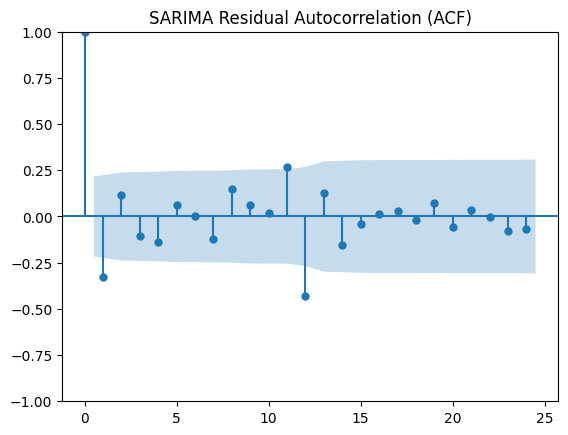

In [33]:
from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt

plt.figure(figsize=(10,4))
plot_acf(sarima_residuals, lags=24)
plt.title("SARIMA Residual Autocorrelation (ACF)")
plt.show()


In [34]:
from statsmodels.stats.diagnostic import acorr_ljungbox

lb_test = acorr_ljungbox(sarima_residuals, lags=[12], return_df=True)
print(lb_test)


      lb_stat  lb_pvalue
12  42.292177    0.00003


In [35]:
# %%
import pickle
import pandas as pd
from pathlib import Path
from pandas.tseries.offsets import MonthBegin
from statsmodels.tsa.statespace.sarimax import SARIMAX

# -----------------------------
# CONFIG (use your repo root)
# -----------------------------
PROJECT_ROOT = Path("/Users/dev/Desktop/graphCeylon-API")

MODELS_DIR   = PROJECT_ROOT / "models" / "recommender_service"
FORECAST_DIR = PROJECT_ROOT / "data" / "recommender_service" / "forecast"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
FORECAST_DIR.mkdir(parents=True, exist_ok=True)

# Your best params
best_sarima_order = (2, 1, 0)
best_sarima_seasonal = (2, 1, 1, 12)

# -----------------------------
# Fit SARIMA on FULL series
# -----------------------------
series_full = df_arrivals["total_arrivals"].astype(float)
series_full = series_full.asfreq("MS")  # ensure monthly
series_full = series_full.interpolate("linear")  # just in case

sarima_full = SARIMAX(
    series_full,
    order=best_sarima_order,
    seasonal_order=best_sarima_seasonal,
    enforce_stationarity=False,
    enforce_invertibility=False,
).fit(disp=False)

# -----------------------------
# Save model (pickle)
# -----------------------------
model_path = MODELS_DIR / "sarima_arrivals_full_2_1_0_2_1_1_12.pkl"
with open(model_path, "wb") as f:
    pickle.dump(sarima_full, f)

print("✅ Saved SARIMA(full) model →", model_path)

# -----------------------------
# Also save a forecast CSV artifact for the API
# -----------------------------
steps = 36  # forecast horizon months (change if you want)
fc_vals = sarima_full.forecast(steps=steps)

last_date = series_full.index.max()
future_index = pd.date_range(start=last_date + MonthBegin(1), periods=steps, freq="MS")

forecast_df = pd.DataFrame({
    "date": future_index,
    "forecast_total_arrivals": fc_vals.values
})

forecast_csv_path = FORECAST_DIR / "sltda_arrivals_sarima_forecast.csv"
forecast_df.to_csv(forecast_csv_path, index=False)

print("✅ Saved SARIMA forecast CSV →", forecast_csv_path)
forecast_df.head()


✅ Saved SARIMA(full) model → /Users/dev/Desktop/graphCeylon-API/models/recommender_service/sarima_arrivals_full_2_1_0_2_1_1_12.pkl
✅ Saved SARIMA forecast CSV → /Users/dev/Desktop/graphCeylon-API/data/recommender_service/forecast/sltda_arrivals_sarima_forecast.csv


,date,forecast_total_arrivals
0,2025-11-01,408851.200007
1,2025-12-01,520991.902240
2,2026-01-01,535000.166144
3,2026-02-01,519784.364591
4,2026-03-01,508471.623425
